# ClaimSight — Exploratory Data Analysis

Dataset: **Car Damage Detection** (Kaggle, `anujms/car-damage-detection`).
Images are organized into `training/` and `validation/` splits, each with
two class folders: `00-damage` and `01-whole`. No masks or bounding boxes
are provided — binary folder labels only.

This notebook answers three questions before any modeling starts:

1. How many images per class and per split — is the dataset balanced?
2. What are the native image dimensions — does the fixed 224x224 resize
   need aspect-ratio handling?
3. What do the images actually look like — what noise should the
   preprocessing pipeline anticipate?


In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.ingestion import EXPECTED_DIRS, dataset_summary
from src.preprocessing import preprocess

plt.rcParams["figure.facecolor"] = "white"
OUT_DIR = Path("../outputs/eda") if Path.cwd().name == "notebooks" else Path("outputs/eda")
OUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path("../data/raw") if Path.cwd().name == "notebooks" else Path("data/raw")


## 1. Class balance per split

In [2]:
summary = dataset_summary(DATA_ROOT)
rows = []
for rel, count in summary.items():
    split, cls = rel.split("/")
    rows.append({"split": split, "class": cls, "count": count})
df_counts = pd.DataFrame(rows)
pivot = df_counts.pivot(index="split", columns="class", values="count")
pivot["total"] = pivot.sum(axis=1)
pivot.loc["total"] = pivot.sum()
pivot


class,00-damage,01-whole,total
split,,,
training,920,920,1840
validation,230,230,460
total,1150,1150,2300


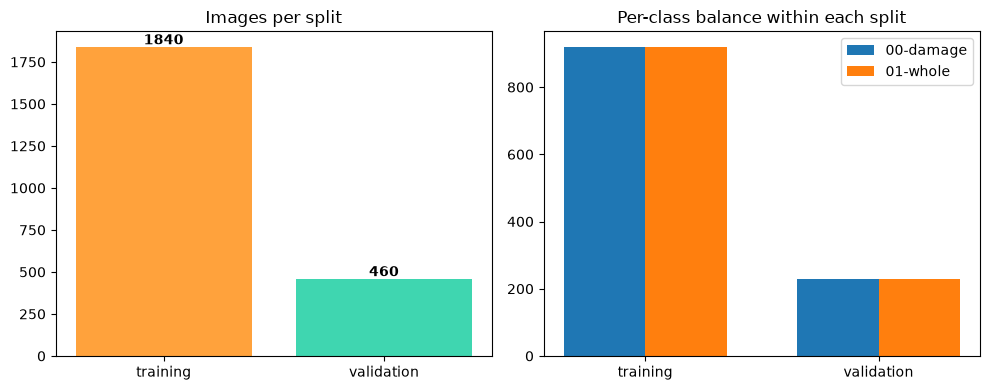

Total images: 2300


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

splits = ["training", "validation"]
totals = [df_counts[df_counts.split == s]["count"].sum() for s in splits]
ax[0].bar(splits, totals, color=["#FFA23C", "#3FD6B0"])
ax[0].set_title("Images per split")
for i, v in enumerate(totals):
    ax[0].text(i, v + 15, str(v), ha="center", fontweight="bold")

classes = ["00-damage", "01-whole"]
x = np.arange(len(splits))
width = 0.35
for i, cls in enumerate(classes):
    vals = [df_counts[(df_counts.split == s) & (df_counts["class"] == cls)]["count"].values[0] for s in splits]
    ax[1].bar(x + i * width, vals, width, label=cls)
ax[1].set_xticks(x + width / 2)
ax[1].set_xticklabels(splits)
ax[1].set_title("Per-class balance within each split")
ax[1].legend()

plt.tight_layout()
plt.savefig(OUT_DIR / "class_balance.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Total images: {sum(totals)}")


**Observation:** the dataset is close to perfectly balanced within each
split (920/920 train, 230/230 validation), so no class-weighting or
resampling is needed in the loss function — a plain `CrossEntropyLoss`
is appropriate.

## 2. Native image dimensions

In [4]:
import random

random.seed(42)
dims = []
for rel in EXPECTED_DIRS:
    folder = DATA_ROOT / rel
    paths = sorted(folder.iterdir())
    sample = random.sample(paths, min(150, len(paths)))
    for p in sample:
        img = cv2.imread(str(p))
        if img is not None:
            h, w = img.shape[:2]
            dims.append({"split_class": rel, "height": h, "width": w})

df_dims = pd.DataFrame(dims)
df_dims.describe()


,height,width
count,600.000000,600.000000
mean,319.963333,460.058333
std,254.482385,372.542662
min,84.000000,112.000000
25%,186.750000,259.000000
50%,194.000000,282.000000
75%,380.500000,600.000000
max,2432.000000,4320.000000


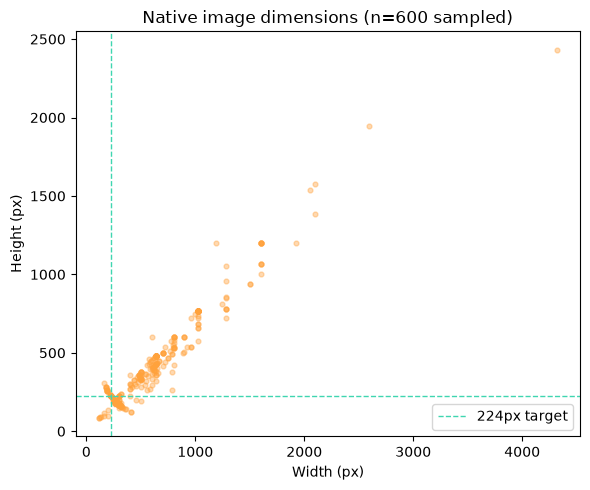

In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(df_dims["width"], df_dims["height"], alpha=0.4, s=12, color="#FFA23C")
ax.set_xlabel("Width (px)")
ax.set_ylabel("Height (px)")
ax.set_title(f"Native image dimensions (n={len(df_dims)} sampled)")
ax.axvline(224, color="#3FD6B0", linestyle="--", linewidth=1, label="224px target")
ax.axhline(224, color="#3FD6B0", linestyle="--", linewidth=1)
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "dimension_scatter.png", dpi=150, bbox_inches="tight")
plt.show()


**Observation:** native resolutions vary substantially and are not
square — this is exactly why the preprocessing pipeline uses an
aspect-preserving letterbox resize instead of a naive stretch-to-224x224,
which would distort dent/scratch geometry.

## 3. Visual sample — raw images per class

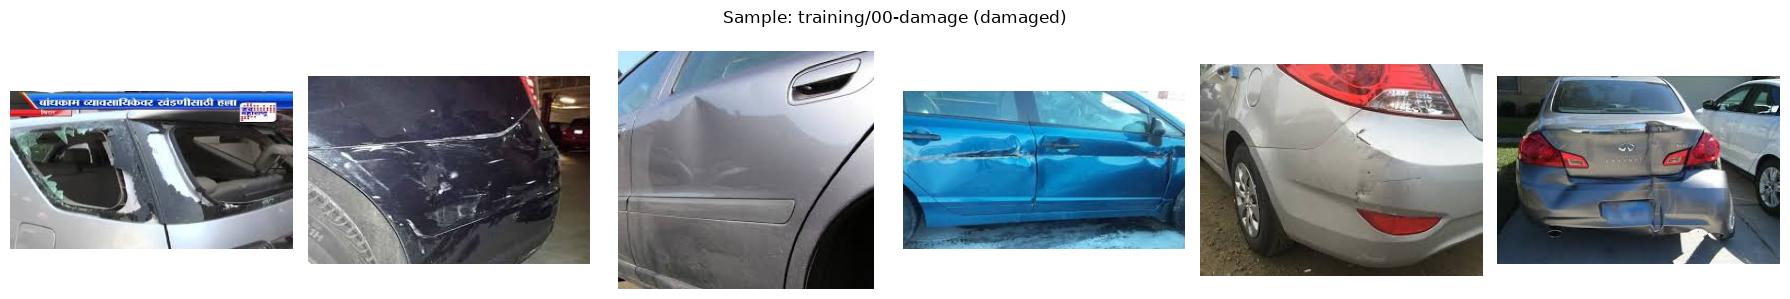

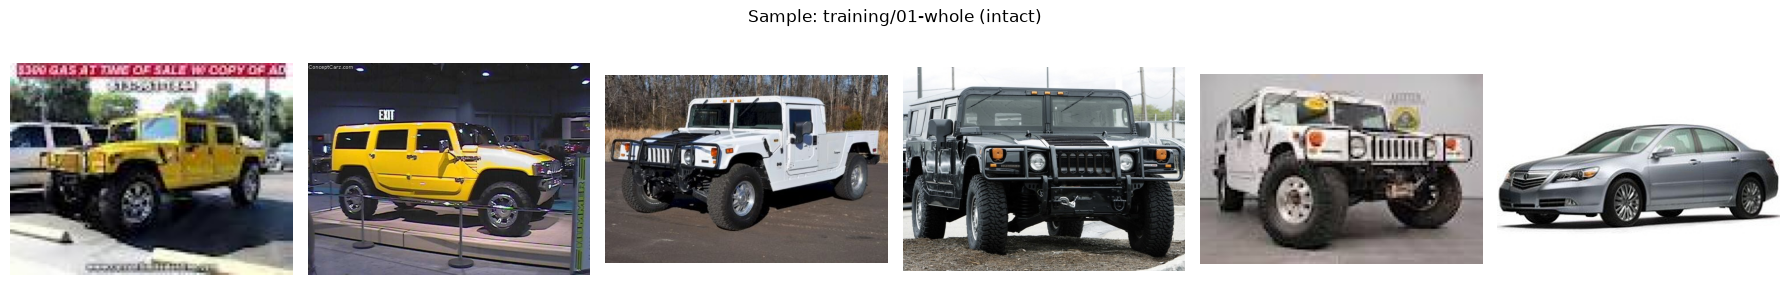

In [6]:
def show_grid(rel_path, title, n=6):
    folder = DATA_ROOT / rel_path
    paths = sorted(folder.iterdir())[:n]
    fig, axes = plt.subplots(1, n, figsize=(3 * n, 3))
    for ax, p in zip(axes, paths):
        img = cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)
        ax.imshow(img)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    return fig

fig = show_grid("training/00-damage", "Sample: training/00-damage (damaged)")
plt.savefig(OUT_DIR / "sample_damage.png", dpi=150, bbox_inches="tight")
plt.show()

fig = show_grid("training/01-whole", "Sample: training/01-whole (intact)")
plt.savefig(OUT_DIR / "sample_whole.png", dpi=150, bbox_inches="tight")
plt.show()


**Observation:** backgrounds, angles, and lighting vary a lot — parking
lots, driveways, dealership floors, different times of day. This is what
motivates both the CLAHE contrast normalization step and the
augmentation policy (flip, small rotation, brightness/contrast) used
only on the training split.

## 4. Preprocessing pipeline — before vs. after

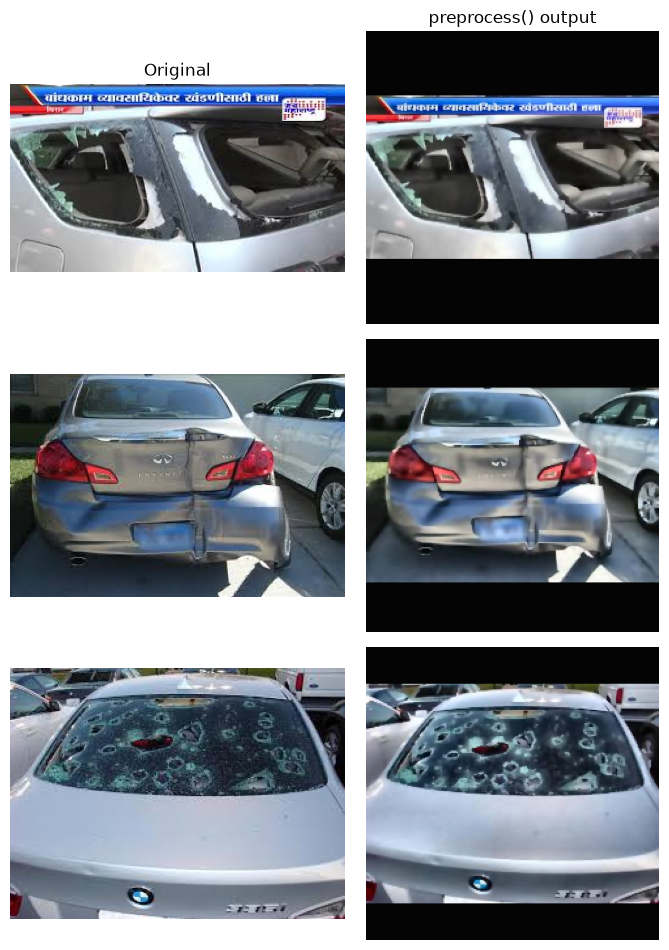

In [7]:
_damage_paths = sorted((DATA_ROOT / "training/00-damage").iterdir())
sample_paths = [_damage_paths[i] for i in [0, 5, 10]]

fig, axes = plt.subplots(len(sample_paths), 2, figsize=(7, 3.2 * len(sample_paths)))
for row, p in enumerate(sample_paths):
    raw_bgr = cv2.imread(str(p))
    raw_rgb = cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB)
    processed = preprocess(raw_bgr)

    axes[row, 0].imshow(raw_rgb)
    axes[row, 0].set_title("Original" if row == 0 else "")
    axes[row, 0].axis("off")

    axes[row, 1].imshow(processed)
    axes[row, 1].set_title("preprocess() output" if row == 0 else "")
    axes[row, 1].axis("off")

plt.tight_layout()
plt.savefig(OUT_DIR / "preprocessing_before_after.png", dpi=150, bbox_inches="tight")
plt.show()


**Observation:** CLAHE visibly recovers shadow detail without blowing
out highlights, and the letterbox padding is clearly visible for
non-square source images — confirming the pipeline behaves as designed
on real data, not just on the synthetic images used in the unit tests.

## Summary

| Question | Finding |
|---|---|
| Class balance | Balanced within each split (920/920 train, 230/230 val) — no class weighting needed |
| Image dimensions | Highly variable, non-square — justifies aspect-preserving letterbox resize |
| Visual noise | Varied backgrounds/angles/lighting — justifies CLAHE + conservative augmentation |
| Dataset size | 2,300 images total (1,840 train / 460 validation) |

These findings directly informed the choices documented in
`src/preprocessing.py` and `src/dataset.py`.
